# 02 · EDA del transporte: los colectivos según la SUBE

**Para qué sirve este notebook.** La hipótesis dice "cuando paran los colectivos". Antes de medir el aire hay
que poder responder con datos: **¿cuándo pararon, y cuánto?** La SUBE registra cada viaje pagado con tarjeta,
así que la cantidad de viajes por línea y por día es un termómetro de cuántos colectivos estaban andando.

**Datos:** `gold_sube_diario` (una fila por día) y `dim_calendario`. Fuente: dataset público de SUBE de la
Secretaría de Transporte (`dat-ab-usos-<año>.csv`), una fila por línea y día.

**Universo:** los colectivos que circulan por la Ciudad son **134 líneas**: las de jurisdicción nacional
(cruzan entre CABA y provincia) y las que son solo de la Ciudad, con número menor a 200. Las líneas
provinciales y municipales casi no entran a CABA y por eso se excluyen (decisión documentada en el pipeline).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Dónde están los Parquet: export/ del repo (local, después de `uv run python run.py`)
# o la carpeta actual (Colab: subir los .parquet de export/ con el panel de archivos).
for BASE in [Path("../export"), Path("export"), Path(".")]:
    if (BASE / "gold_analitico.parquet").exists():
        break
else:
    raise FileNotFoundError("No encuentro gold_analitico.parquet: corré `uv run python run.py` o subilo a Colab")

d = pd.read_parquet(BASE / "gold_analitico.parquet")
d["fecha"] = pd.to_datetime(d["fecha"])
eventos = pd.read_parquet(BASE / "eventos.parquet")
eventos["fecha"] = pd.to_datetime(eventos["fecha"])

ESTACIONES = ["CENTENARIO", "CORDOBA", "LA BOCA"]
# Un color fijo por estación en todos los notebooks (paleta validada para daltonismo).
COLOR = {"CENTENARIO": "#2a78d6", "CORDOBA": "#eb6834", "LA BOCA": "#1baf7a"}
# Resaltado de eventos (solo en gráficos donde no se colorea por estación).
COLOR_EVENTO = {"sin_colectivos": "#6250d6", "control": "#eda100"}
GRIS, TINTA, TINTA_2 = "#b9b8b2", "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "figure.dpi": 110, "font.size": 10, "text.color": TINTA,
    "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 11,
    "lines.linewidth": 2, "legend.frameon": False,
})
pd.options.display.float_format = "{:,.2f}".format
print(f"{len(d):,} filas (estación × día), {d.fecha.min():%d/%m/%Y} a {d.fecha.max():%d/%m/%Y}")

2,950 filas (estación × día), 01/01/2024 a 30/09/2026


In [2]:
sube = pd.read_parquet(BASE / "gold_sube_diario.parquet")
cal = pd.read_parquet(BASE / "dim_calendario.parquet").drop(columns="es_dia_normal")
s = sube.merge(cal, on="fecha")
s["fecha"] = pd.to_datetime(s["fecha"])
s = s.sort_values("fecha").reset_index(drop=True)
print(f"{len(s):,} días, {s.fecha.min():%d/%m/%Y} a {s.fecha.max():%d/%m/%Y}")
s.head(3)

1,029 días, 01/01/2024 a 25/10/2026


,fecha,es_dia_normal,usos_colectivo,usos_tren,usos_subte,usos_colectivo_caba,ratio_colectivo,ratio_tren,ratio_subte,ratio_colectivo_caba,...,pct_paradas_interjurisdiccionales,anio,mes,dia_semana,nombre_dia,feriado,tipo_dia,evento,grupo_evento,pct_lineas_paradas_caba
0,2024-01-01,False,"1,563,487.00","127,531.00","105,515.00","742,024.00",0.20,0.12,0.21,0.20,...,12.33,2024,1,1,lunes,Año nuevo,feriado,NaN,NaN,NaN
1,2024-01-02,False,"6,888,911.00","987,882.00","612,423.00","3,244,372.00",0.89,0.91,1.18,0.85,...,0.00,2024,1,2,martes,NaN,hábil,NaN,NaN,NaN
2,2024-01-03,True,"7,608,652.00","1,059,615.00","660,061.00","3,565,825.00",0.99,1.00,1.26,0.93,...,0.00,2024,1,3,miércoles,NaN,hábil,NaN,NaN,NaN


## 1. ¿Cuánta gente viaja?

Mediana de viajes por día según el tipo de día. `usos_colectivo` es todo el AMBA; `usos_colectivo_caba`
es solo el universo de líneas que circulan por la Ciudad.

In [3]:
MODOS = {"usos_colectivo_caba": "Colectivos por CABA", "usos_colectivo": "Colectivos AMBA",
         "usos_tren": "Trenes", "usos_subte": "Subte"}
(s.groupby("tipo_dia")[list(MODOS)].median().rename(columns=MODOS)
   .reindex(["hábil", "sábado", "domingo", "feriado"]) / 1e6).round(2).rename_axis("millones de viajes por día")

,Colectivos por CABA,Colectivos AMBA,Trenes,Subte
millones de viajes por día,,,,
hábil,4.25,8.78,1.05,0.52
sábado,2.46,5.33,0.58,0.26
domingo,1.44,2.87,0.20,0.14
feriado,1.57,3.22,0.29,0.17


In [4]:
participacion = (s.usos_colectivo_caba / s.usos_colectivo)
print(f"Las líneas que circulan por CABA son el {participacion.median():.0%} de los viajes en colectivo del AMBA.")

Las líneas que circulan por CABA son el 48% de los viajes en colectivo del AMBA.


**Lectura.** Un día hábil típico hay unos 4,25 millones de viajes en las líneas que cruzan la Ciudad, la mitad
de todo el AMBA, y el colectivo mueve muchísima más gente que el tren y el subte juntos. Un domingo viaja
un tercio de la gente de un día hábil.

## 2. Evolución en el tiempo

Viajes diarios en las líneas que circulan por CABA (línea fina: todos los días, incluidos fines de semana).
La línea gruesa es la mediana móvil de 28 días **de los días hábiles normales**: el nivel de un día típico.

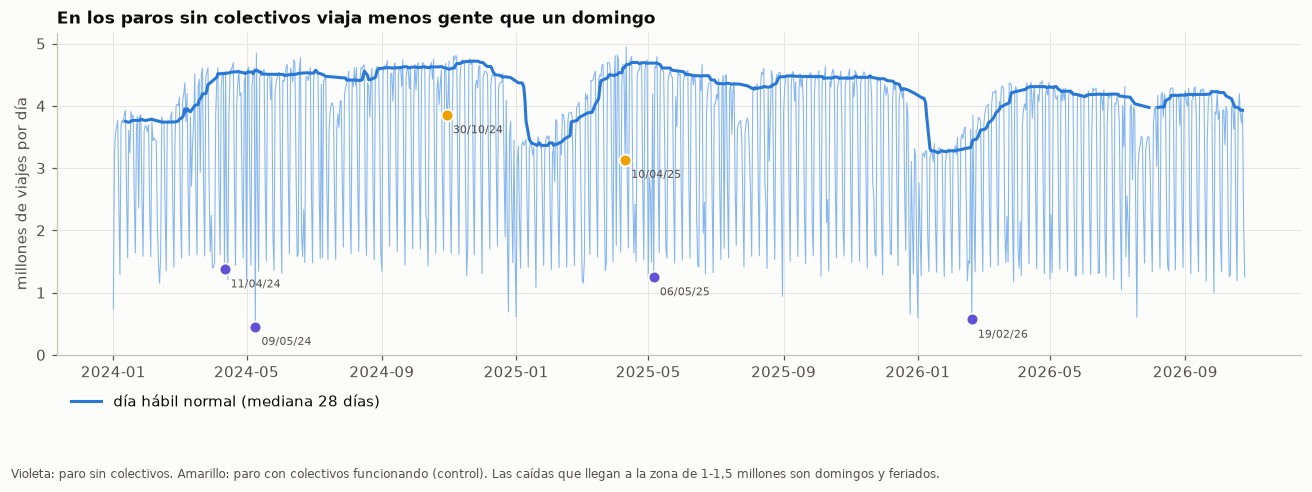

In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
serie = s.set_index("fecha").sort_index()["usos_colectivo_caba"] / 1e6
ax.plot(serie.index, serie.values, color="#86b6ef", lw=0.7)
tipico = (s[s.es_dia_normal].set_index("fecha")["usos_colectivo_caba"] / 1e6).rolling("28D", min_periods=8).median()
ax.plot(tipico.index, tipico.values, color="#2a78d6", lw=2, label="día hábil normal (mediana 28 días)")
for _, ev in eventos.iterrows():
    v = serie.get(ev.fecha)
    color = COLOR_EVENTO[ev.grupo]
    ax.scatter(ev.fecha, v, s=60, color=color, edgecolor="#fcfcfb", linewidth=1.2, zorder=3)
    ax.annotate(f"{ev.fecha:%d/%m/%y}", (ev.fecha, v), xytext=(4, -12), textcoords="offset points",
                fontsize=7.5, color=TINTA_2)
ax.set_ylabel("millones de viajes por día")
ax.set_ylim(0, None)
ax.set_title("En los paros sin colectivos viaja menos gente que un domingo")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.08))
fig.text(0.01, -0.1, "Violeta: paro sin colectivos. Amarillo: paro con colectivos funcionando (control). "
         "Las caídas que llegan a la zona de 1-1,5 millones son domingos y feriados.", fontsize=8, color=TINTA_2)
plt.tight_layout()

In [6]:
normales = s[s.es_dia_normal]
anual = normales.groupby("anio")["usos_colectivo_caba"].agg(dias="size", mediana="median")
anual["mediana"] = (anual["mediana"] / 1e6).round(2)
anual["vs 2024"] = (anual["mediana"] / anual.loc[2024, "mediana"] - 1).mul(100).round(1)
anual.rename(columns={"mediana": "millones de viajes (día hábil normal)", "vs 2024": "% vs 2024"})

,dias,millones de viajes (día hábil normal),% vs 2024
anio,,,
2024,196,4.48,0.00
2025,202,4.41,-1.60
2026,166,4.13,-7.80


**Lectura.** El uso del colectivo en un día hábil normal viene bajando: en 2026 se viaja un 8% menos que en 2024.
Por eso la actividad de cada día **no se compara contra un promedio fijo**, sino contra los días hábiles
normales de las semanas vecinas (ver punto 4): así una caída de la demanda a lo largo de los años no se
confunde con un paro.

## 3. Ciclo semanal por modo

Mediana de viajes por día de la semana, como porcentaje del lunes a viernes de cada modo.

,Colectivos por CABA,Trenes,Subte
dia_semana,,,
1,98.00,99.00,97.00
2,101.00,100.00,100.00
3,100.00,99.00,101.00
4,100.00,101.00,101.00
5,101.00,102.00,99.00
6,58.00,56.00,50.00
7,34.00,19.00,27.00


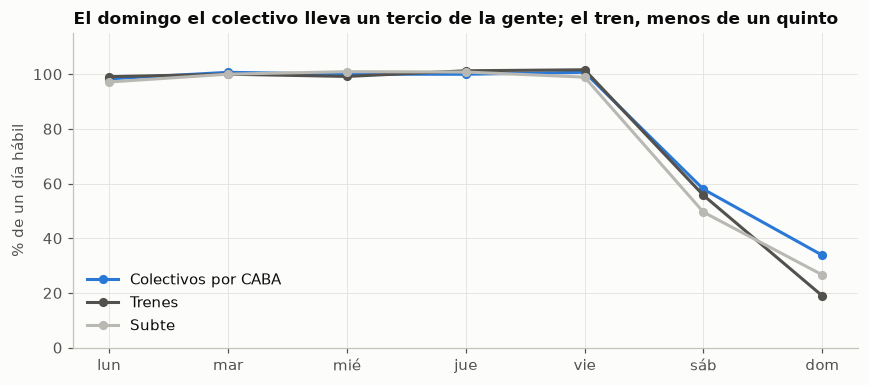

In [7]:
DIAS = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
sin_feriados = s[s.tipo_dia != "feriado"]
semana = sin_feriados.groupby("dia_semana")[["usos_colectivo_caba", "usos_tren", "usos_subte"]].median()
semana = semana / semana.loc[1:5].median() * 100
fig, ax = plt.subplots(figsize=(8, 3.6))
for col, nombre, color in [("usos_colectivo_caba", "Colectivos por CABA", "#2a78d6"),
                           ("usos_tren", "Trenes", TINTA_2), ("usos_subte", "Subte", GRIS)]:
    ax.plot(range(7), semana[col].values, marker="o", markersize=5, color=color, label=nombre)
ax.set_xticks(range(7), DIAS)
ax.set_ylabel("% de un día hábil")
ax.set_ylim(0, 115)
ax.legend(loc="lower left")
ax.set_title("El domingo el colectivo lleva un tercio de la gente; el tren, menos de un quinto")
plt.tight_layout()
semana.round(0).rename(columns=MODOS)

## 4. ¿Qué es un "día normal"? (la referencia de todo el estudio)

Para comparar un paro hace falta saber cómo es un día sin nada raro. Definimos **día hábil normal**: lunes
a viernes, no feriado, y con **colectivo, tren y subte por encima del 90%** de su uso habitual (la mediana del
mismo día de la semana en las 4 semanas anteriores y posteriores). El umbral del 90% deja afuera vacaciones,
fiestas, días de paro de cualquier modo y días con problemas en trenes o subte, sin necesidad de un
calendario externo.

Días hábiles sin evento: 684 · normales: 564 (82%)


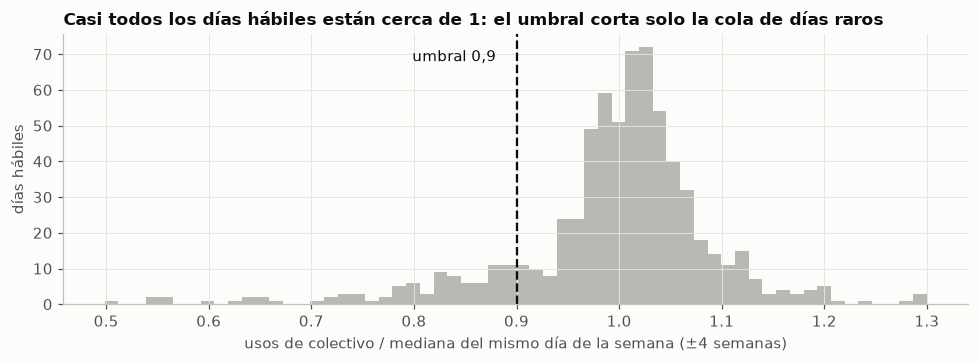

In [8]:
habiles = s[(s.tipo_dia == "hábil") & s.evento.isna()]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(habiles.ratio_colectivo.clip(upper=1.3), bins=60, color=GRIS)
ax.axvline(0.9, color=TINTA, lw=1.5, ls="--")
ax.text(0.89, ax.get_ylim()[1] * 0.9, "umbral 0,9  ", ha="right", color=TINTA)
ax.set(xlabel="usos de colectivo / mediana del mismo día de la semana (±4 semanas)", ylabel="días hábiles")
ax.set_title("Casi todos los días hábiles están cerca de 1: el umbral corta solo la cola de días raros")
plt.tight_layout()
print(f"Días hábiles sin evento: {len(habiles)} · normales: {habiles.es_dia_normal.sum()} "
      f"({habiles.es_dia_normal.mean():.0%})")

In [9]:
baja = habiles[~habiles.es_dia_normal]
print("Hábiles de baja actividad por mes (todos los años):")
print(baja.groupby("mes").size().reindex(range(1, 13), fill_value=0).to_frame("días").T.to_string())
cual = pd.DataFrame({m: baja[f"ratio_{m}"] < 0.9 for m in ["colectivo", "tren", "subte"]})
print("\n¿Qué modo estuvo por debajo del 90%? (un día puede tener varios)")
print(cual.sum().rename("días").to_string())

Hábiles de baja actividad por mes (todos los años):
mes   1   2   3   4   5   6   7   8   9   10  11  12
días   9  11   7   9   5   5  31  10  12  10   2   9

¿Qué modo estuvo por debajo del 90%? (un día puede tener varios)
colectivo    89
tren         68
subte        52


**Lectura.** El 82% de los días hábiles sin evento son "normales". Los que quedan afuera se concentran en julio
(vacaciones de invierno). En muchos de ellos el colectivo anda bien y el que falla es el tren o el subte: por
eso se exige que los **tres** modos estén normales, para que la referencia sea un día realmente típico.

## 5. La dosis de cada paro: ¿cuántas líneas pararon?

Para cada línea y día se compara la cantidad de viajes contra la mediana de esa misma línea en días normales
del mismo día de la semana (±3 semanas). **Una línea "paró" si tuvo menos del 15% de sus viajes habituales.**
La dosis es el porcentaje de líneas paradas, **ponderado por el tamaño de cada línea** (que pare la 60 pesa
más que una línea chica). Se calcula de lunes a viernes; los fines de semana no hay base de comparación.

In [10]:
cols = {"pct_lineas_paradas_ponderado": "% líneas paradas (ponderado)",
        "pct_paradas_solo_caba": "solo CABA", "pct_paradas_interjurisdiccionales": "nacionales",
        "actividad_colectivo_vs_habil": "actividad colectivos", "ratio_tren": "tren vs habitual",
        "ratio_subte": "subte vs habitual"}
ev_sube = (s[s.evento.notna()].set_index(["fecha", "evento", "grupo_evento"])[list(cols)]
             .rename(columns=cols).sort_index(level="grupo_evento", ascending=False))
ev_sube.style.format("{:.2f}").format("{:.0f}", subset=["% líneas paradas (ponderado)", "solo CABA", "nacionales"])

,,,% líneas paradas (ponderado),solo CABA,nacionales,actividad colectivos,tren vs habitual,subte vs habitual
fecha,evento,grupo_evento,,,,,,
2026-02-19 00:00:00,Paro general CGT,sin_colectivos,67,69,67,0.15,0.00,0.00
2025-05-06 00:00:00,Paro UTA,sin_colectivos,63,65,63,0.27,0.67,1.00
2024-05-09 00:00:00,Paro general CGT,sin_colectivos,68,54,72,0.10,0.00,0.00
2024-04-11 00:00:00,Paro UTA,sin_colectivos,67,56,69,0.30,0.83,1.01
2025-04-10 00:00:00,Paro general CGT con colectivos funcionando,control,0,0,0,0.67,0.00,0.00
2024-10-30 00:00:00,Paro de trenes y subte,control,0,0,0,0.82,0.00,0.00


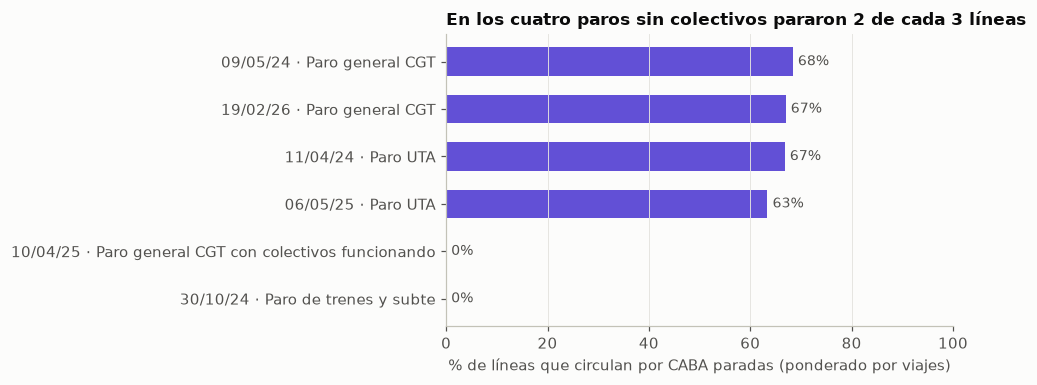

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.6))
orden = ev_sube.reset_index().sort_values("% líneas paradas (ponderado)")
y = np.arange(len(orden))
colores = [COLOR_EVENTO[g] for g in orden.grupo_evento]
ax.barh(y, orden["% líneas paradas (ponderado)"], color=colores, height=0.6)
for yi, v in zip(y, orden["% líneas paradas (ponderado)"]):
    ax.text(v + 1, yi, f"{v:.0f}%", va="center", color=TINTA_2, fontsize=9)
ax.set_yticks(y, [f"{f:%d/%m/%y} · {e}" for f, e in zip(orden.fecha, orden.evento)])
ax.set_xlim(0, 100)
ax.set_xlabel("% de líneas que circulan por CABA paradas (ponderado por viajes)")
ax.set_title("En los cuatro paros sin colectivos pararon 2 de cada 3 líneas")
ax.grid(axis="y", visible=False)
plt.tight_layout()

**Lectura.**
- En los **cuatro paros sin colectivos** paró entre el 63% y el 68% de las líneas (ponderado). No es el 100%:
  algunas empresas no adhieren y algunos trabajadores van igual. Paran parejo las líneas solo porteñas y
  las nacionales.
- En los **paros generales** (09/05/2024 y 19/02/2026) además pararon trenes y subte: la actividad de colectivos
  cae a 0,10-0,15. En los **paros de la UTA** (11/04/2024 y 06/05/2025) el subte funcionó normal.
- En los **controles** no paró ninguna línea (0%), pero trenes y subte sí: son días con otros cambios en la
  movilidad pero con colectivos. Por eso sirven de comparación.

## 6. ¿Se nos escapó algún paro?

Si el catálogo de eventos está completo, los únicos días hábiles con muchas líneas paradas deberían ser los
del estudio. Días de lunes a viernes con más del 5% de líneas paradas:

In [12]:
(s[(s.pct_lineas_paradas_ponderado > 5)]
   .sort_values("pct_lineas_paradas_ponderado", ascending=False)
   [["fecha", "nombre_dia", "tipo_dia", "feriado", "evento", "pct_lineas_paradas_ponderado",
     "actividad_colectivo_vs_habil"]]
   .round({"pct_lineas_paradas_ponderado": 1, "actividad_colectivo_vs_habil": 2}))

,fecha,nombre_dia,tipo_dia,feriado,evento,pct_lineas_paradas_ponderado,actividad_colectivo_vs_habil
129,2024-05-09,jueves,hábil,NaN,Paro general CGT,68.40,0.10
780,2026-02-19,jueves,hábil,NaN,Paro general CGT,67.00,0.15
101,2024-04-11,jueves,hábil,NaN,Paro UTA,66.80,0.30
491,2025-05-06,martes,hábil,NaN,Paro UTA,63.40,0.27
724,2025-12-25,jueves,feriado,Navidad,NaN,35.20,0.16
359,2024-12-25,miércoles,feriado,Navidad,NaN,31.40,0.16
731,2026-01-01,jueves,feriado,Año nuevo,NaN,25.40,0.18
366,2025-01-01,miércoles,feriado,Año nuevo,NaN,23.60,0.17
0,2024-01-01,lunes,feriado,Año nuevo,NaN,13.00,0.20
66,2024-03-07,jueves,hábil,NaN,NaN,7.00,0.90


**Lectura.** Fuera de los cuatro paros, los únicos días con más del 5% de líneas paradas son **25 de diciembre
y 1 de enero** (feriados en los que muchas líneas hacen servicio reducido) y el **07/03/2024**, con un 7%
(probablemente un conflicto en alguna empresa, a verificar en la prensa): demasiado chico para usarlo como evento. **El catálogo está completo**:
no hay paros grandes de colectivos en el período que no estén en el estudio. Además, el pipeline tiene un
test (`eventos_coherentes_con_sube`) que falla si alguien carga un evento que no coincide con la SUBE.

## Hallazgos del EDA de transporte

1. **Universo:** 134 líneas que circulan por CABA, la mitad de los viajes en colectivo del AMBA (~4,25 millones
   por día hábil).
2. **La demanda baja en el tiempo** (2026, un 8% por debajo de 2024): por eso la referencia de cada día son sus
   semanas vecinas y no un promedio fijo.
3. **Día hábil normal:** colectivo, tren y subte por encima del 90% de lo habitual. Es el 82% de los hábiles.
4. **Dosis de los paros:** 63-68% de las líneas paradas en los cuatro paros sin colectivos; 0% en los controles.
5. **El catálogo de eventos está completo:** fuera de esos cuatro días, ningún día hábil supera el 7% de líneas
   paradas salvo Navidad y Año Nuevo.
6. **Limitación:** la SUBE cuenta viajes pagados, no colectivos en la calle ni kilómetros recorridos dentro de la
   Ciudad. Una línea que circula vacía no se distingue de una parada, pero en un paro eso es poco frecuente.